# 3. Classification - Predict PHA

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.5f}'.format)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

os.makedirs('models', exist_ok=True)
os.makedirs('results', exist_ok=True)

Load pandas, sklearn models, metrics, SMOTE, XGBoost and joblib for saving; create output folders. Numbers are shown as normal values (like 3,810,113.98854) instead of scientific notation (3.810114e+06).

## Read the data

In [2]:
data = pd.read_csv('classification.csv')
data.head()

,H,e,a,i,pha
0,3.40000,0.07601,2.76917,10.59407,0
1,4.20000,0.22997,2.77384,34.83293,0
2,5.33000,0.25694,2.66829,12.99104,0
3,3.00000,0.08872,2.36142,7.14177,0
4,6.90000,0.19091,2.57404,5.36743,0


Read the classification data (H, e, a, i, pha) made in notebook 2.

In [3]:
data.shape

(932336, 5)

Confirm the size of the data.

## Class balance

In [4]:
print(data['pha'].value_counts())
print()
print(data['pha'].value_counts(normalize=True) * 100)

pha
0    930270
1      2066
Name: count, dtype: int64

pha
0   99.77841
1    0.22159
Name: proportion, dtype: float64


See how rare PHAs are (0.22%), which is why we need balancing and recall-based evaluation.

## Transform features (log for a)

In [5]:
def make_features(df):
    new = pd.DataFrame()
    new['H'] = df['H']
    new['e'] = df['e']
    new['a'] = np.log1p(df['a'])
    new['i'] = df['i']
    return new

X = make_features(data)
y = data['pha']
X.head()

,H,e,a,i
0,3.40000,0.07601,1.32685,10.59407
1,4.20000,0.22997,1.32809,34.83293
2,5.33000,0.25694,1.29972,12.99104
3,3.00000,0.08872,1.21236,7.14177
4,6.90000,0.19091,1.27370,5.36743


Apply the same transform (log of a) in one function so the app can repeat it exactly.

## Train test split (stratify keeps the same PHA % in both)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.sum(), y_test.sum())

(745868, 4) (186468, 4)
1653 413


Keep 20% of asteroids unseen for testing; stratify keeps the same PHA share in train and test.

## Function to get all metrics

In [7]:
def get_metrics(name, balancing, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        'Model': name,
        'Balancing': balancing,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC_AUC': roc_auc_score(y_test, y_prob)
    }

One function to score every model the same way, so the comparison is fair.

## Ratio of non-PHA to PHA (used by XGBoost for balancing)

In [8]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
ratio

np.float64(450.2208106473079)

The non-PHA to PHA ratio is the weight XGBoost uses to balance the classes.

## Models without balancing

In [9]:
models_normal = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
}

Three models with no balancing, as a baseline.

## Models with class_weight balancing

In [10]:
models_weighted = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, scale_pos_weight=ratio, random_state=42, n_jobs=-1)
}

The same three models told to weigh PHA mistakes more (class_weight).

## Models for SMOTE data

In [11]:
models_smote = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
}

The same three models, to be trained on SMOTE-balanced data.

## Scale the training data and apply SMOTE (only on training data)

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print('Before SMOTE:', y_train.value_counts().to_dict())
print('After SMOTE :', pd.Series(y_train_smote).value_counts().to_dict())

Before SMOTE: {0: 744215, 1: 1653}
After SMOTE : {0: 744215, 1: 744215}


SMOTE creates synthetic PHAs in the training data only, so the test set stays real.

## MLflow setup

In [13]:
os.environ['GIT_PYTHON_REFRESH'] = 'quiet'
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'

import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('PHA_Classification')

2026/11/20 17:48:43 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/20 17:48:43 INFO mlflow.store.db.utils: Updating database tables


2026/11/20 17:48:44 INFO mlflow.tracking.fluent: Experiment with name 'PHA_Classification' does not exist. Creating a new experiment.


<Experiment: artifact_location=('file:C:/Users/Chandrasekar A/Documents/Kiro/Planetary Defense '
 'Analytics/mlruns/1'), creation_time=1795177124555, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1795177124555, lifecycle_stage='active', name='PHA_Classification', tags={}, trace_location=None, workspace='default'>

Set up MLflow so every training run is recorded with its settings and scores.

## Train all 9 models and log them to MLflow

In [14]:
results = []
trained = {}

for balancing, model_dict in [('None', models_normal), ('class_weight', models_weighted), ('SMOTE', models_smote)]:
    for name, model in model_dict.items():

        if balancing == 'SMOTE':
            model.fit(X_train_smote, y_train_smote)
            pipe = Pipeline([('scaler', scaler), ('model', model)])
        else:
            pipe = Pipeline([('scaler', StandardScaler()), ('model', model)])
            pipe.fit(X_train, y_train)

        row = get_metrics(name, balancing, pipe, X_test, y_test)
        results.append(row)
        trained[name + ' | ' + balancing] = pipe

        with mlflow.start_run(run_name=name + ' | ' + balancing):
            mlflow.log_param('model', name)
            mlflow.log_param('balancing', balancing)
            mlflow.log_params(model.get_params())
            mlflow.log_metric('accuracy', row['Accuracy'])
            mlflow.log_metric('precision', row['Precision'])
            mlflow.log_metric('recall', row['Recall'])
            mlflow.log_metric('f1', row['F1'])
            mlflow.log_metric('roc_auc', row['ROC_AUC'])
            mlflow.sklearn.log_model(pipe, name='model', serialization_format='cloudpickle')

        print(name, '|', balancing, '| done')

2026/11/20 17:48:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression | None | done


2026/11/20 17:49:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest | None | done


2026/11/20 17:49:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost | None | done


... (8 outputs left out)

2026/11/20 17:50:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest | SMOTE | done


2026/11/20 17:50:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost | SMOTE | done


Train all 9 combinations, score them on the test set and log each run to MLflow.

## Compare all models

In [15]:
results_df = pd.DataFrame(results)
results_df = results_df.round(4)
results_df.to_csv('results/classification_results.csv', index=False)
results_df

,Model,Balancing,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,None,0.99740,0.24360,0.09200,0.13360,0.99290
1,Random Forest,None,0.99820,0.70160,0.32450,0.44370,0.99880
2,XGBoost,None,0.99810,0.61260,0.32930,0.42830,0.99760
3,Logistic Regression,class_weight,0.98360,0.11900,0.99760,0.21260,0.99340
4,Random Forest,class_weight,0.99550,0.32440,0.96370,0.48540,0.99580
5,XGBoost,class_weight,0.99480,0.28700,0.91040,0.43640,0.99810
6,Logistic Regression,SMOTE,0.98430,0.12320,0.99270,0.21920,0.99340
7,Random Forest,SMOTE,0.99540,0.31960,0.95880,0.47940,0.99590
8,XGBoost,SMOTE,0.99600,0.35330,0.95880,0.51630,0.99870


Put all 9 results in one table and save it.

## Plot recall, precision and F1

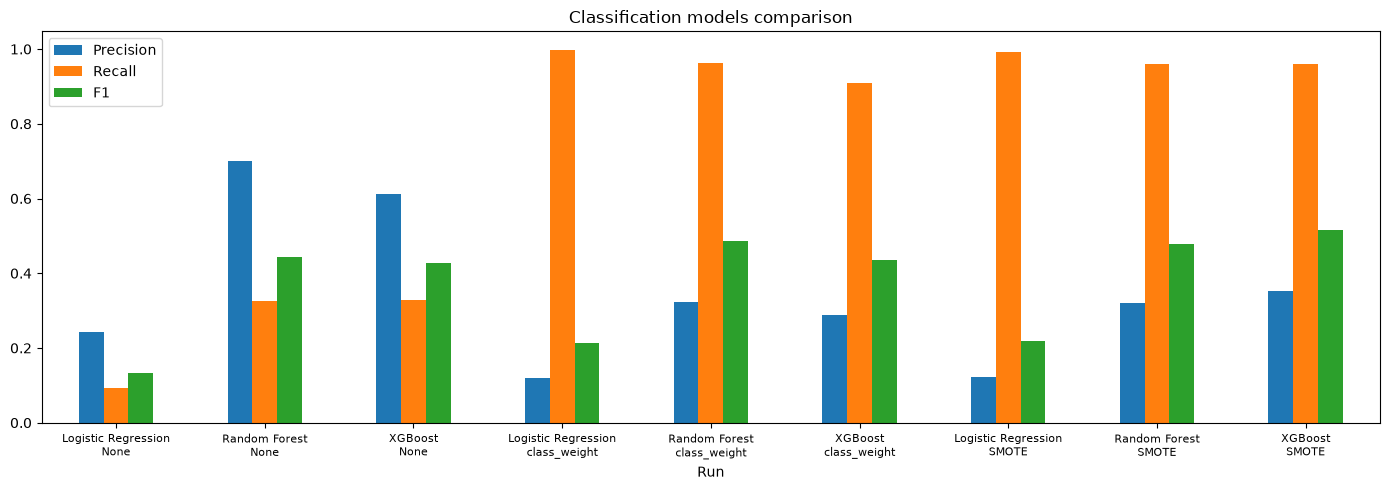

In [16]:
results_df['Run'] = results_df['Model'] + '\n' + results_df['Balancing']

results_df.set_index('Run')[['Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(14, 5))
plt.title('Classification models comparison')
plt.xticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig('images/classification_comparison.png')
plt.show()

A chart makes precision, recall and F1 of all 9 runs easy to compare.

# Evaluation of all models

## Confusion matrix of all 9 models (rows: balancing, columns: algorithm)

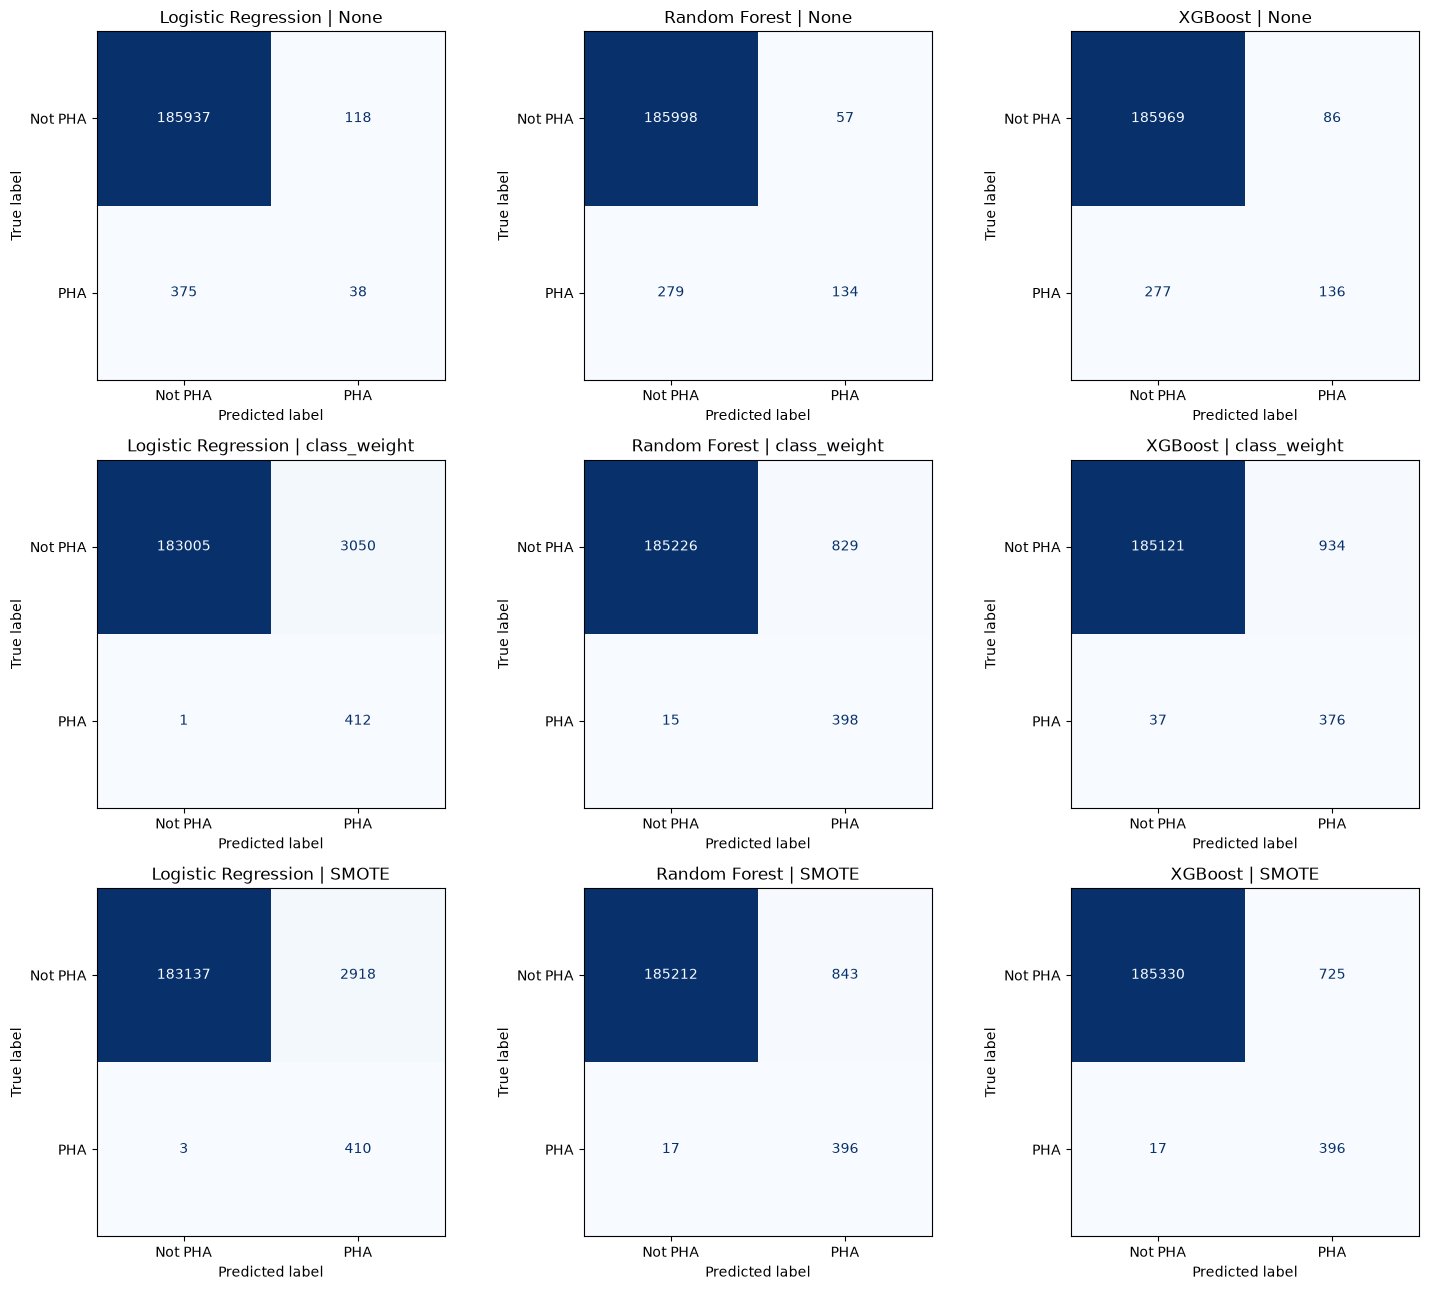

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
names = list(trained.keys())

for n in range(len(names)):
    ax = axes[n // 3][n % 3]
    y_pred = trained[names[n]].predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Not PHA', 'PHA']).plot(
        ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(names[n])

plt.tight_layout()
plt.savefig('images/confusion_matrix_all.png')
plt.show()

Confusion matrices show exactly how many PHAs each model caught or missed.

## Missed PHAs and false alarms for every model

In [18]:
miss_rows = []
for name, pipe in trained.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pipe.predict(X_test)).ravel()
    miss_rows.append({'Run': name, 'PHA caught (TP)': tp, 'PHA missed (FN)': fn, 'False alarms (FP)': fp})

miss_df = pd.DataFrame(miss_rows)
miss_df.to_csv('results/classification_errors.csv', index=False)
miss_df

,Run,PHA caught (TP),PHA missed (FN),False alarms (FP)
0,Logistic Regression | None,38,375,118
1,Random Forest | None,134,279,57
2,XGBoost | None,136,277,86
3,Logistic Regression | class_weight,412,1,3050
4,Random Forest | class_weight,398,15,829
5,XGBoost | class_weight,376,37,934
6,Logistic Regression | SMOTE,410,3,2918
7,Random Forest | SMOTE,396,17,843
8,XGBoost | SMOTE,396,17,725


Count missed PHAs and false alarms, the two mistakes that matter in planetary defense.

## Best balancing for each of the 3 algorithms (highest F1)

In [19]:
best_each = results_df.sort_values('F1', ascending=False).groupby('Model').head(1)
best_each = best_each.drop(columns=['Run'])
best_each

,Model,Balancing,Accuracy,Precision,Recall,F1,ROC_AUC
8,XGBoost,SMOTE,0.99600,0.35330,0.95880,0.51630,0.99870
4,Random Forest,class_weight,0.99550,0.32440,0.96370,0.48540,0.99580
6,Logistic Regression,SMOTE,0.98430,0.12320,0.99270,0.21920,0.99340


Find the best balancing for each algorithm, to compare the 3 algorithms fairly.

## Classification report of each algorithm

In [20]:
for _, row in best_each.iterrows():
    name = row['Model'] + ' | ' + row['Balancing']
    print('=====', name)
    print(classification_report(y_test, trained[name].predict(X_test), target_names=['Not PHA', 'PHA']))

===== XGBoost | SMOTE


              precision    recall  f1-score   support

     Not PHA       1.00      1.00      1.00    186055
         PHA       0.35      0.96      0.52       413

    accuracy                           1.00    186468
   macro avg       0.68      0.98      0.76    186468
weighted avg       1.00      1.00      1.00    186468

===== Random Forest | class_weight
              precision    recall  f1-score   support

     Not PHA       1.00      1.00      1.00    186055
         PHA       0.32      0.96      0.49       413

    accuracy                           1.00    186468
   macro avg       0.66      0.98      0.74    186468
weighted avg       1.00      1.00      1.00    186468

===== Logistic Regression | SMOTE


              precision    recall  f1-score   support

     Not PHA       1.00      0.98      0.99    186055
         PHA       0.12      0.99      0.22       413

    accuracy                           0.98    186468
   macro avg       0.56      0.99      0.61    186468
weighted avg       1.00      0.98      0.99    186468



Detailed precision, recall and F1 for each algorithm.

## ROC curve and Precision-Recall curve of the 3 algorithms

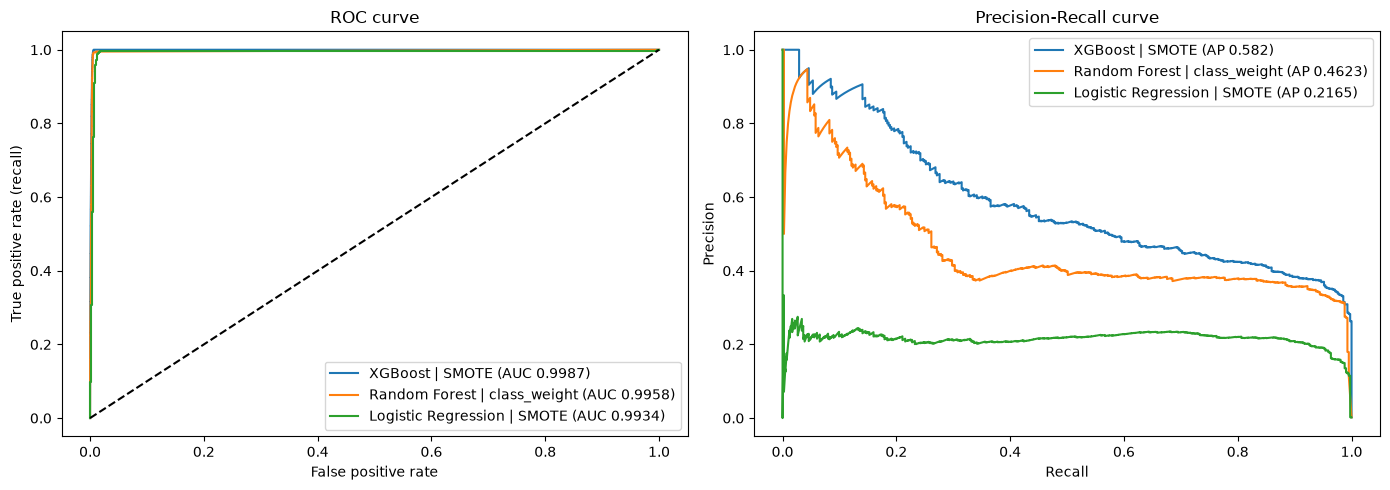

In [21]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

plt.figure(figsize=(14, 5))

for _, row in best_each.iterrows():
    name = row['Model'] + ' | ' + row['Balancing']
    y_prob = trained[name].predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, label=name + ' (AUC ' + str(round(row['ROC_AUC'], 4)) + ')')

    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    plt.subplot(1, 2, 2)
    plt.plot(recall, precision, label=name + ' (AP ' + str(round(average_precision_score(y_test, y_prob), 4)) + ')')

plt.subplot(1, 2, 1)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.title('ROC curve')
plt.legend()

plt.subplot(1, 2, 2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curve')
plt.legend()

plt.tight_layout()
plt.savefig('images/roc_pr_curves.png')
plt.show()

Curves compare models at every threshold, not just at 0.5.

## Pick the best model: highest F1 among models with recall >= 0.80 (missing a PHA is costly)

In [22]:
good = results_df[results_df['Recall'] >= 0.80]
best_row = good.sort_values('F1', ascending=False).iloc[0]
best_name = best_row['Model'] + ' | ' + best_row['Balancing']
best_model = trained[best_name]

print('Best model:', best_name)
best_row

Best model: XGBoost | SMOTE


Model               XGBoost
Balancing             SMOTE
Accuracy            0.99600
Precision           0.35330
Recall              0.95880
F1                  0.51630
ROC_AUC             0.99870
Run          XGBoost\nSMOTE
Name: 8, dtype: object

Choose the best model with a clear rule: recall >= 80% first, then highest F1.

## Why this model is the best

In [23]:
print('Rule 1: recall must be at least 80% (do not miss hazardous asteroids)')
print('Rule 2: among those, highest F1 (fewest false alarms for that recall)')
print()

ranked = results_df.sort_values('F1', ascending=False)
for _, row in ranked.iterrows():
    name = row['Model'] + ' | ' + row['Balancing']
    missed = miss_df[miss_df['Run'] == name]['PHA missed (FN)'].values[0]
    alarms = miss_df[miss_df['Run'] == name]['False alarms (FP)'].values[0]
    if name == best_name:
        reason = 'SELECTED - recall >= 80% and highest F1'
    elif row['Recall'] < 0.80:
        reason = 'rejected - recall below 80%'
    else:
        reason = 'rejected - recall ok but lower F1 (more false alarms)'
    print(name.ljust(36), 'Recall', format(row['Recall'], '.4f'), ' F1', format(row['F1'], '.4f'),
          ' missed', str(missed).rjust(3), ' false alarms', str(alarms).rjust(5), ' ->', reason)

Rule 1: recall must be at least 80% (do not miss hazardous asteroids)
Rule 2: among those, highest F1 (fewest false alarms for that recall)

XGBoost | SMOTE                      Recall 0.9588  F1 0.5163  missed  17  false alarms   725  -> SELECTED - recall >= 80% and highest F1
Random Forest | class_weight         Recall 0.9637  F1 0.4854  missed  15  false alarms   829  -> rejected - recall ok but lower F1 (more false alarms)
Random Forest | SMOTE                Recall 0.9588  F1 0.4794  missed  17  false alarms   843  -> rejected - recall ok but lower F1 (more false alarms)
Random Forest | None                 Recall 0.3245  F1 0.4437  missed 279  false alarms    57  -> rejected - recall below 80%
XGBoost | class_weight               Recall 0.9104  F1 0.4364  missed  37  false alarms   934  -> rejected - recall ok but lower F1 (more false alarms)
XGBoost | None                       Recall 0.3293  F1 0.4283  missed 277  false alarms    86  -> rejected - recall below 80%
Logistic Regr

Print why each model was selected or rejected, so the choice is explained.

## Confusion matrix of best model

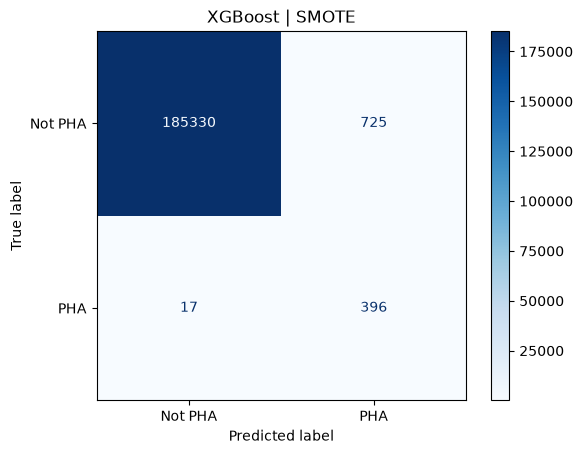

In [24]:
y_pred = best_model.predict(X_test)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Not PHA', 'PHA']).plot(cmap='Blues', values_format='d')
plt.title(best_name)
plt.savefig('images/confusion_matrix_best.png')
plt.show()

Confusion matrix of the chosen model.

## Classification report of best model

In [25]:
print(classification_report(y_test, y_pred, target_names=['Not PHA', 'PHA']))

              precision    recall  f1-score   support

     Not PHA       1.00      1.00      1.00    186055
         PHA       0.35      0.96      0.52       413

    accuracy                           1.00    186468
   macro avg       0.68      0.98      0.76    186468
weighted avg       1.00      1.00      1.00    186468



Full report of the chosen model on both classes.

## Confusion matrix of the model without balancing (same algorithm) for comparison

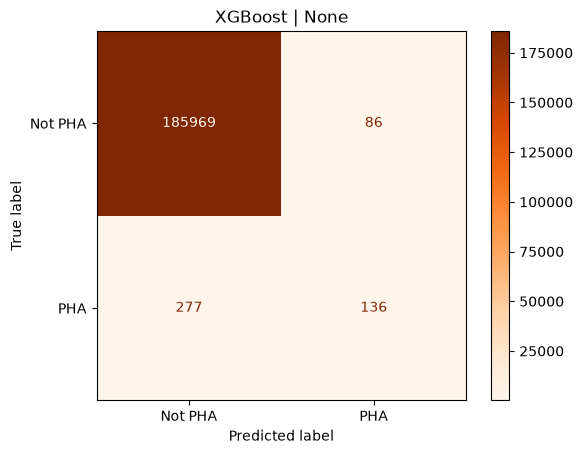

In [26]:
normal_name = best_row['Model'] + ' | None'
y_pred_normal = trained[normal_name].predict(X_test)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_normal), display_labels=['Not PHA', 'PHA']).plot(cmap='Oranges', values_format='d')
plt.title(normal_name)
plt.savefig('images/confusion_matrix_no_balancing.png')
plt.show()

Same algorithm without balancing, to show how much balancing helped.

## Save the best model

In [27]:
joblib.dump(best_model, 'models/pha_model.pkl')
print('Saved', best_name)

Saved XGBoost | SMOTE


Save the best model so the app can use it without retraining.

# SHAP - explain the best model

In [28]:
import shap

shap_sample = X_test.sample(1000, random_state=42)
shap_scaled = pd.DataFrame(best_model.named_steps['scaler'].transform(shap_sample), columns=X.columns)

model_only = best_model.named_steps['model']
if best_row['Model'] == 'Logistic Regression':
    explainer = shap.LinearExplainer(model_only, shap_scaled)
else:
    explainer = shap.TreeExplainer(model_only)

shap_values = explainer(shap_scaled)

if len(shap_values.values.shape) == 3:
    shap_values = shap_values[:, :, 1]

Set up SHAP to explain how the best model makes its decisions.

## SHAP summary plot

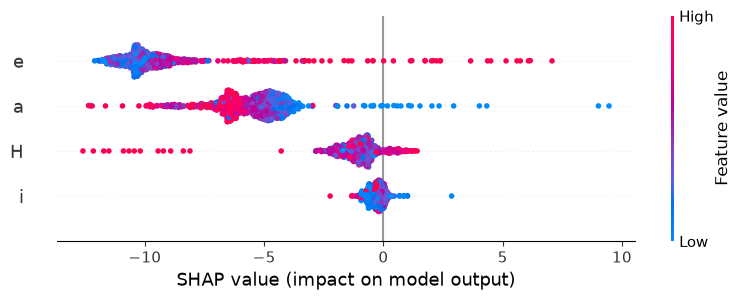

In [29]:
shap.summary_plot(shap_values, shap_scaled, show=False)
plt.tight_layout()
plt.savefig('images/shap_summary_pha.png')
plt.show()

Summary plot shows which features matter most and in which direction.

## SHAP feature importance (bar)

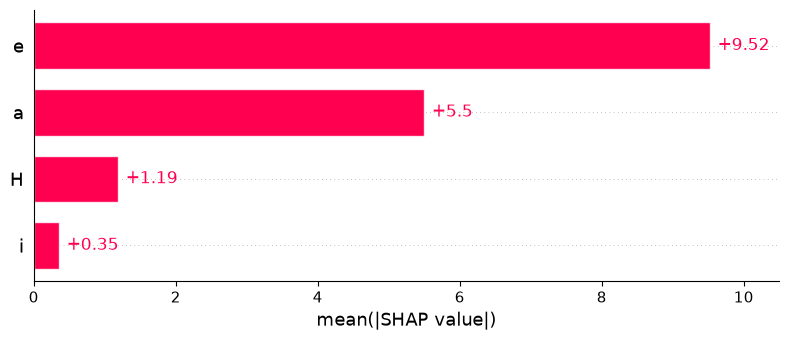

In [30]:
shap.plots.bar(shap_values, show=False)
plt.tight_layout()
plt.savefig('images/shap_bar_pha.png')
plt.show()

Bar plot shows the overall importance of each feature.

## SHAP waterfall for one PHA asteroid

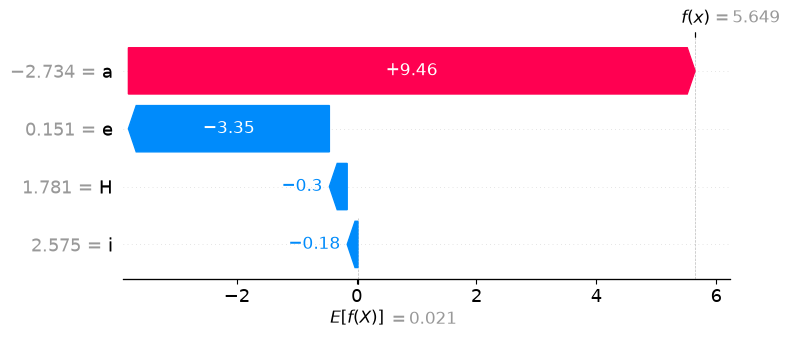

In [31]:
pha_index = np.where(y_test.loc[shap_sample.index].values == 1)[0]
if len(pha_index) > 0:
    idx = pha_index[0]
else:
    idx = 0

shap.plots.waterfall(shap_values[idx], show=False)
plt.tight_layout()
plt.savefig('images/shap_waterfall_pha.png')
plt.show()

Waterfall shows why one real PHA was predicted as hazardous.